Harry Ferguson - CIS 361 - Summer 2026 - Assignment #4

In [8]:
from collections import defaultdict
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import itertools

training_words, training_tags, test_words, test_tags = [], [], [], []

# Read training and test data from files
def read_pos_file(file_path, words, tags):
    with open(file_path, "r", encoding="utf-8") as file:
        for line in file:
            parts = line.strip().split("\t")
            if len(parts) < 2:
                continue
            words.append(parts[0].lower())
            tags.append(parts[1])

read_pos_file('WSJ_02-21.pos', training_words, training_tags)
read_pos_file('WSJ_24.pos', test_words, test_tags)

print('Number of training words: ', len(training_words))
print('Number of training tags: ', len(training_tags))
print('Number of test words: ', len(test_words))
print('Number of training words: ', len(test_tags))

class HMM:
    def __init__(self):
        self.transition_probabilities = defaultdict(lambda: defaultdict(float))
        self.emission_probabilities = defaultdict(lambda: defaultdict(float))
        self.tag_set = set()
        self.word_set = set()

    def fit(self, words, tags):
        assert len(words) == len(tags), "Number of words and tags must match"

        transition_dict = defaultdict(lambda: defaultdict(int))
        num_tags = len(tags)
        for i in range(num_tags - 1):
            transition_dict[tags[i]][tags[i+1]] += 1
            self.transition_probabilities['<start>'][tags[i]] = 1 / num_tags # set initial start state for each tag to the same value

        for tag1 in transition_dict:
            total_transitions = sum(transition_dict[tag1].values())
            transition_dict[tag1]['<start>'] = total_transitions
            for tag2 in transition_dict[tag1]:
                self.transition_probabilities[tag1][tag2] = transition_dict[tag1][tag2] / total_transitions

        emission_dict = defaultdict(lambda: defaultdict(int))
        for word, tag in zip(words, tags):
            emission_dict[tag][word] += 1

        for tag in emission_dict:
            total_emissions = sum(emission_dict[tag].values())
            for word in emission_dict[tag]:
                self.emission_probabilities[tag][word] = emission_dict[tag][word] / total_emissions
        
        self.tag_set = set(tags)
        self.word_set = set(words)

    def predict(self, sentence):
        sentence = [word.lower() for word in sentence]
        viterbi = [{}]
        backpointer = [{}]

        for tag in self.tag_set:
            transition_prob = self.transition_probabilities['<start>'].get(tag, 0)
            emission_prob = self.emission_probabilities[tag].get(sentence[0], 0) if sentence[0] in self.word_set else 1e-6
            viterbi[0][tag] = transition_prob * emission_prob
            backpointer[0][tag] = None
        
        for t in range(1, len(sentence)):
            viterbi.append({})
            backpointer.append({})
            for tag in self.tag_set:
                max_prob = max(viterbi[t-1][prev_tag] * self.transition_probabilities[prev_tag].get(tag, 0) * self.emission_probabilities[tag].get(sentence[t], 0) if sentence[t] in self.word_set else 1e-6 for prev_tag in self.tag_set)
                viterbi[t][tag] = max_prob
                backpointer[t][tag] = max(self.tag_set, key=lambda prev_tag: viterbi[t-1][prev_tag] * self.transition_probabilities[prev_tag].get(tag, 0))

        # This section finds the maximum probability in the last column of the viterbi matrix and identifies the tag associated with that maximum probability.
        # Termination step
        best_path_prob = max(viterbi[-1].values())
        best_path = [list(viterbi[-1].keys())[list(viterbi[-1].values()).index(best_path_prob)]]
        current_tag = best_path[0]
        for t in range(len(sentence)-1, 0, -1):
            current_tag = backpointer[t][current_tag]
            best_path.insert(0, current_tag)

        return best_path

hmm = HMM()
hmm.fit(training_words, training_tags)

predicted_tags = hmm.predict(test_words)

ground_truth_tags = test_tags
accuracy = accuracy_score(ground_truth_tags, predicted_tags)
precision = precision_score(ground_truth_tags, predicted_tags, average='macro', zero_division=1)
recall = recall_score(ground_truth_tags, predicted_tags, average='macro', zero_division=1)
f1 = f1_score(ground_truth_tags, predicted_tags, average='macro')

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

Number of training words:  950028
Number of training tags:  950028
Number of test words:  32853
Number of training words:  32853
Accuracy: 0.7743280674519831
Precision: 0.7438494506231135
Recall: 0.7264787332937508
F1-score: 0.6939539486648203


Confusion matrix, without normalization


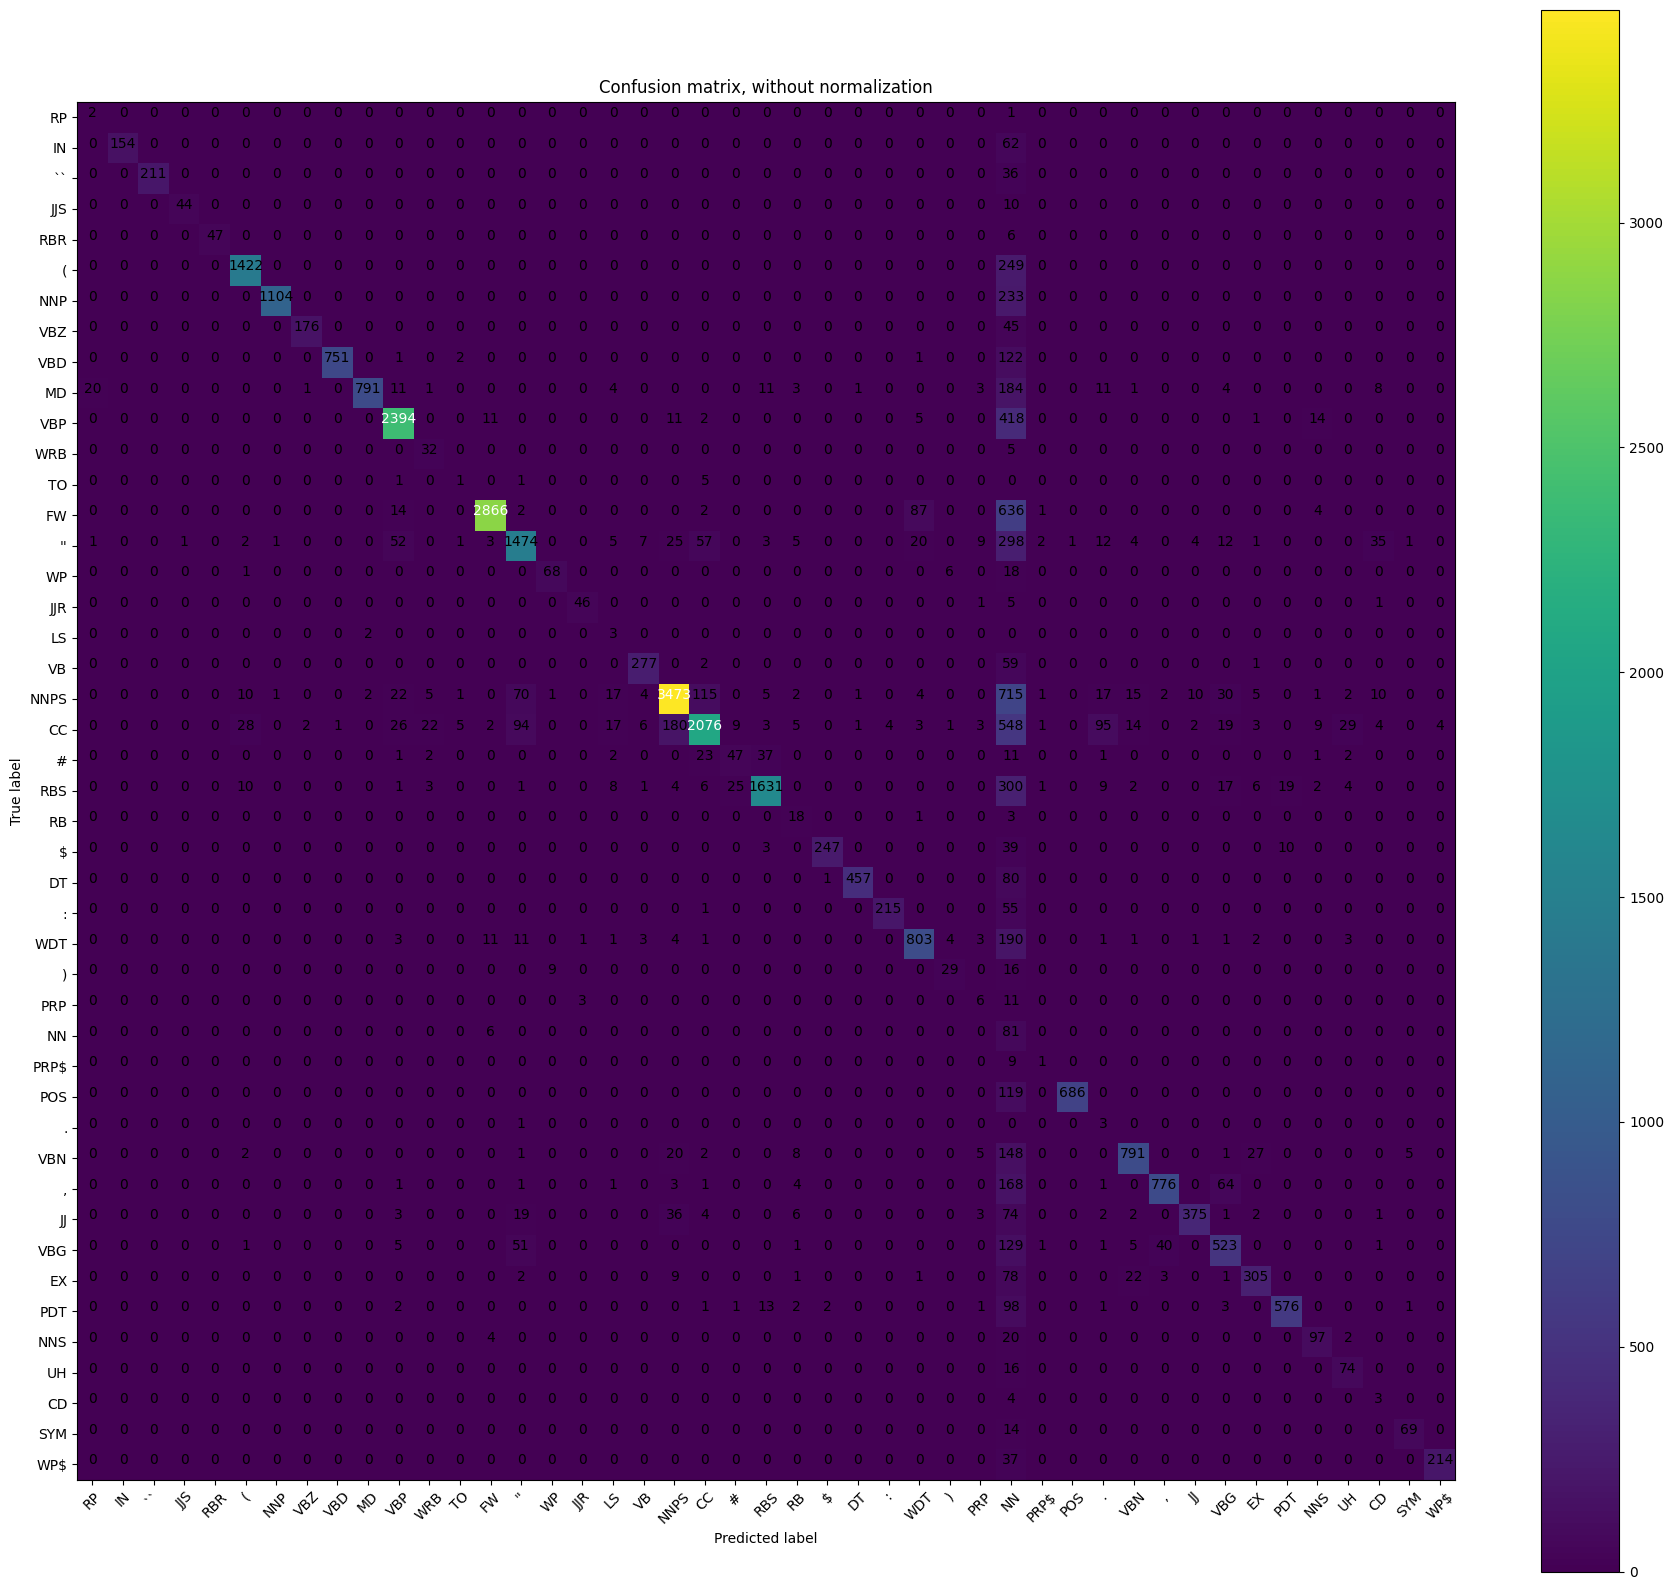

In [9]:
cm = confusion_matrix(ground_truth_tags, predicted_tags)

def plot_confusion_matrix(cm, classes, normalize=False, title='Confusion matrix'):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    plt.figure(figsize=(18, 16))
    plt.imshow(cm, interpolation='nearest')
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    fmt = '.2f' if normalize else 'd'
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

# Plot non-normalized confusion matrix
plot_confusion_matrix(cm, classes=set(ground_truth_tags + predicted_tags), title='Confusion matrix, without normalization')

plt.show()

In [19]:

nouns = set()
for i in range(len(predicted_tags)):
    if predicted_tags[i] == 'NN':
        nouns.add(test_words[i])
nouns_not_in_training = nouns & set(training_words)
#print(nouns_not_in_training)
count = 0
for n in nouns_not_in_training:
    count += test_words.count(n)
print('Total number of words in the test data that are not in the training data: ', count)


Total number of words in the test data that are not in the training data:  7591


The training data consists of 950028 words, each with an associated tag. The test data consisted of 32853 words, with each also having an associated tag. After training the model, it correctly predicted approximately 77.4% of the tags in the test data. As can be seen from the confusion matrix, the vast majority of misclassifications made by the model is when the model identified a tag as NN (noun, singular or mass) when in reality the correct tag was something else. I believe that the cause of most of these errors is the presence in the test data of words not in the training data. There are 7591 such words, making up 23.1% of all test words, which is close to the 22.6% of the tags mislabeled by the model.